In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp


def feature_diagnostics(df, name):
    return pd.DataFrame({
        "dataset": name,
        "feature": df.columns,
        "mean": df.mean().values,
        "std": df.std().values,
        "variance": df.var().values,
        "min": df.min().values,
        "q01": df.quantile(0.01).values,
        "q05": df.quantile(0.05).values,
        "q25": df.quantile(0.25).values,
        "median": df.quantile(0.50).values,
        "q75": df.quantile(0.75).values,
        "q95": df.quantile(0.95).values,
        "q99": df.quantile(0.99).values,
        "max": df.max().values,
        "missing_pct": df.isna().mean().values * 100,
        "unique_values": df.nunique(dropna=True).values,
    })

def range_tail_report(df_n, df_a):
    rows = []

    for f in df_n.columns:
        x_n = df_n[f].dropna()
        x_a = df_a[f].dropna()

        n_min = x_n.min()
        n_max = x_n.max()
        n_q01 = x_n.quantile(0.01)
        n_q05 = x_n.quantile(0.05)
        n_q95 = x_n.quantile(0.95)
        n_q99 = x_n.quantile(0.99)

        inside_minmax = (x_a >= n_min) & (x_a <= n_max)

        below_min = x_a < n_min
        above_max = x_a > n_max

        inside_5_95 = (x_a >= n_q05) & (x_a <= n_q95)
        below_q05 = x_a < n_q05
        above_q95 = x_a > n_q95

        inside_1_99 = (x_a >= n_q01) & (x_a <= n_q99)
        below_q01 = x_a < n_q01
        above_q99 = x_a > n_q99

        # "Inside range but in tails" means:
        # anomaly is still within normal min/max, but outside the normal 5%-95% central region.
        inside_range_but_tail_5_95 = inside_minmax & (~inside_5_95)

        rows.append({
            "feature": f,

            "normal_min": n_min,
            "normal_q01": n_q01,
            "normal_q05": n_q05,
            "normal_q95": n_q95,
            "normal_q99": n_q99,
            "normal_max": n_max,

            "anomaly_min": x_a.min(),
            "anomaly_max": x_a.max(),

            "anom_inside_normal_minmax_pct": inside_minmax.mean() * 100,
            "anom_below_normal_min_pct": below_min.mean() * 100,
            "anom_above_normal_max_pct": above_max.mean() * 100,

            "anom_inside_normal_5_95_pct": inside_5_95.mean() * 100,
            "anom_below_normal_q05_pct": below_q05.mean() * 100,
            "anom_above_normal_q95_pct": above_q95.mean() * 100,
            "anom_outside_normal_5_95_pct": (below_q05 | above_q95).mean() * 100,
            "anom_inside_range_but_tail_5_95_pct": inside_range_but_tail_5_95.mean() * 100,

            "anom_inside_normal_1_99_pct": inside_1_99.mean() * 100,
            "anom_outside_normal_1_99_pct": (below_q01 | above_q99).mean() * 100,
        })

    return pd.DataFrame(rows)

def ecdf(x):
    x = np.sort(x)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


def plot_hist_and_ecdf(df_n, df_a, features, bins=100, chunk_size=5):
    # Loop through the features list in steps of `chunk_size`
    for i in range(0, len(features), chunk_size):
        chunk_features = features[i:i + chunk_size]
        n_features = len(chunk_features)

        # Create a new figure for this specific batch of features
        fig, axes = plt.subplots(
            n_features, 2,
            figsize=(14, 3 * n_features)
        )

        # Handle the edge case where the last chunk only has 1 feature left
        if n_features == 1:
            axes = np.array([axes])

        for row, feature in enumerate(chunk_features):
            x_n = df_n[feature].dropna().values
            x_a = df_a[feature].dropna().values

            # Shared bins
            combined = np.concatenate([x_n, x_a])
            bin_edges = np.histogram_bin_edges(combined, bins=bins)

            # Histogram
            ax = axes[row, 0]
            ax.hist(x_n, bins=bin_edges, density=True, alpha=0.5, label="normal")
            ax.hist(x_a, bins=bin_edges, density=True, alpha=0.5, label="slow/anomaly")
            ax.set_title(f"{feature} - histogram")
            ax.legend()

            # ECDF
            ax = axes[row, 1]
            xn_sorted, yn = ecdf(x_n)
            xa_sorted, ya = ecdf(x_a)

            ks_stat, p_value = ks_2samp(x_n, x_a)

            ax.plot(xn_sorted, yn, label="normal")
            ax.plot(xa_sorted, ya, label="slow/anomaly")
            ax.set_title(f"{feature} - ECDF | KS={ks_stat:.3f}")
            ax.set_ylabel("Cumulative probability")
            ax.legend()

        plt.tight_layout()
        plt.show()



    return ks_df

def get_ks_df(df_n, df_a, top_k = 10):
  ks_scores = []
  for col in df_n.columns:
      stat, p = ks_2samp(df_n[col].dropna(), df_a[col].dropna())
      ks_scores.append((col, stat, p))

  ks_df = pd.DataFrame(ks_scores, columns=["feature", "ks_stat", "p_value"])
  ks_df = ks_df.sort_values("ks_stat", ascending=False).head(top_k)

  return ks_df


def plot_most_separable_features(df_n, df_a, features):
    plot_hist_and_ecdf(df_n=df_n, df_a=df_a, features=features)

In [17]:
# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

NORMAL_PATH = "../data/KukaNormal.npy"
ANOMALY_PATH = "../data/KukaSlow.npy"
COLUMNS_PATH = "../data/KukaColumnNames.npy"


xn = np.load(NORMAL_PATH)
xa = np.load(ANOMALY_PATH)[:, : -1]
columns = np.load(COLUMNS_PATH)[:-1]


df_n = pd.DataFrame(xn, columns=columns)
df_a = pd.DataFrame(xa, columns=columns)

# **DATASET BASIC INFORMATION**

In [18]:
overview = pd.DataFrame({
    "dataset": ["normal", "slow/anomaly"],
    "rows": [df_n.shape[0], df_a.shape[0]],
    "features": [df_n.shape[1], df_a.shape[1]],
    "missing_values": [df_n.isna().sum().sum(), df_a.isna().sum().sum()],
    "inf_values": [np.isinf(df_n.values).sum(), np.isinf(df_a.values).sum()],
    "duplicate_rows": [df_n.duplicated().sum(), df_a.duplicated().sum()],
})

display(overview)

,dataset,rows,features,missing_values,inf_values,duplicate_rows
0,normal,233792,86,0,0,158
1,slow/anomaly,41538,86,0,0,16


In [19]:
# ------------------------------------------------------------
# 2. Basic feature diagnostics
# ------------------------------------------------------------

diag_n = feature_diagnostics(df_n, "normal")
diag_a = feature_diagnostics(df_a, "slow/anomaly")

# **ALMOST-CONSTANT FEATURES**

**Near-constant threshold:** `std < {LOW_VARIANCE_THRESHOLD}`

A feature is considered almost constant when its std is below a given threshold. These features should therefore be considered useless for the autoencoder because they do not carry information.

,feature,std,variance,min,max,unique_values,missing_pct,is_constant,is_near_constant
85,sensor_id7_temp,2.842177e-14,8.077970e-28,180.240000,180.240000,1,0.00%,False,True
74,sensor_id6_temp,2.842177e-14,8.077970e-28,180.240000,180.240000,1,0.00%,False,True
63,sensor_id5_temp,8.526531e-14,7.270173e-27,144.120000,144.120000,1,0.00%,False,True
30,sensor_id2_temp,8.526531e-14,7.270173e-27,144.120000,144.120000,1,0.00%,False,True
77,sensor_id7_AccZ,1.220245e-02,1.488997e-04,0.827148,1.143555,434,0.00%,False,False
76,sensor_id7_AccY,1.796907e-02,3.228876e-04,-0.224609,0.331543,543,0.00%,False,False
40,sensor_id3_q4,2.345308e-02,5.500470e-04,-0.081069,0.248984,228242,0.00%,False,False
6,machine_nameKuka Robot_power_factor,2.508125e-02,6.290689e-04,0.761271,0.924396,16419,0.00%,False,False
39,sensor_id3_q3,2.594895e-02,6.733480e-04,-0.115349,0.175234,228242,0.00%,False,False
3,machine_nameKuka Robot_frequency,3.204013e-02,1.026570e-03,49.902534,50.097847,5,0.00%,False,False


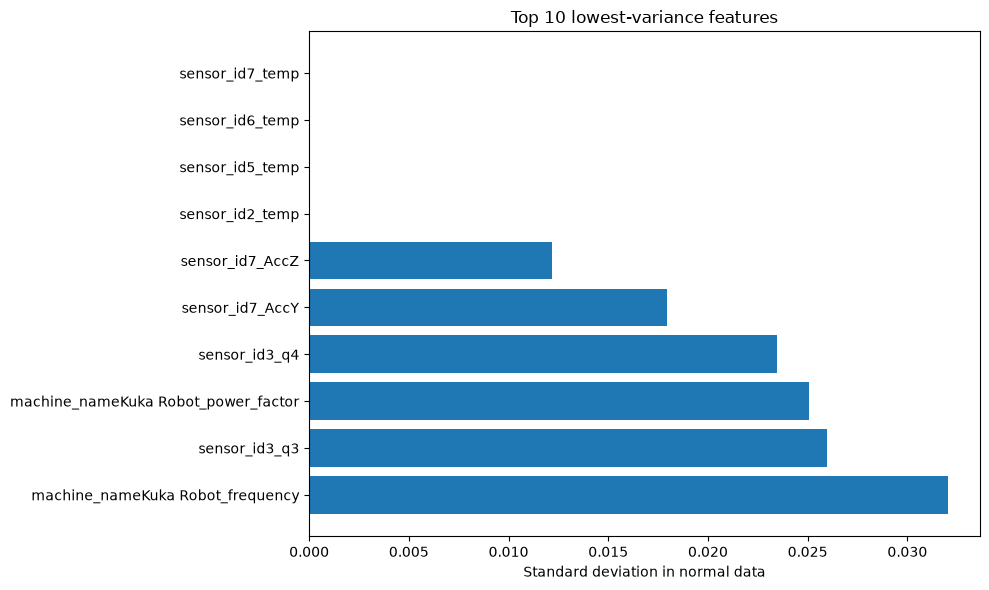

Constant features: 0
Near-constant features: 4


In [20]:
LOW_VARIANCE_THRESHOLD = 1e-8
TOP_K_LOW_VAR = 10

low_var_report_n = diag_n[[
    "feature", "std", "variance", "min", "max", "unique_values", "missing_pct"
]].copy()


low_var_report_n["is_constant"] = low_var_report_n["std"] == 0
low_var_report_n["is_near_constant"] = low_var_report_n["std"] < LOW_VARIANCE_THRESHOLD

low_var_report_n = low_var_report_n.sort_values("std", ascending=True)

display(
    low_var_report_n.head(TOP_K_LOW_VAR).style
    .background_gradient(subset=["std", "variance", "unique_values"], cmap="Blues")
    .format({
        "std": "{:.6e}",
        "variance": "{:.6e}",
        "min": "{:.6f}",
        "max": "{:.6f}",
        "missing_pct": "{:.2f}%",
    })
)

# Bar plot: lowest-variance features
plt.figure(figsize=(10, 6))
plot_df = low_var_report_n.head(TOP_K_LOW_VAR).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["std"])
plt.xlabel("Standard deviation in normal data")
plt.title(f"Top {TOP_K_LOW_VAR} lowest-variance features")
plt.tight_layout()
plt.show()

constant_features = low_var_report_n.loc[low_var_report_n["is_constant"], "feature"].tolist()
near_constant_features = low_var_report_n.loc[low_var_report_n["is_near_constant"], "feature"].tolist()

print(f"Constant features: {len(constant_features)}")
print(f"Near-constant features: {len(near_constant_features)}")


,feature,std,variance,min,max,unique_values,missing_pct,is_constant,is_near_constant
85,sensor_id7_temp,2.842205e-14,8.078130e-28,180.240000,180.240000,1,0.00%,False,True
74,sensor_id6_temp,2.842205e-14,8.078130e-28,180.240000,180.240000,1,0.00%,False,True
63,sensor_id5_temp,2.842205e-14,8.078130e-28,144.120000,144.120000,1,0.00%,False,True
41,sensor_id3_temp,2.842205e-14,8.078130e-28,144.120000,144.120000,1,0.00%,False,True
30,sensor_id2_temp,2.842205e-14,8.078130e-28,144.120000,144.120000,1,0.00%,False,True
77,sensor_id7_AccZ,7.988283e-03,6.381267e-05,0.865234,1.206543,239,0.00%,False,False
76,sensor_id7_AccY,1.258236e-02,1.583158e-04,-0.169434,0.208496,328,0.00%,False,False
39,sensor_id3_q3,1.432303e-02,2.051493e-04,-0.047778,0.069972,40346,0.00%,False,False
71,sensor_id6_q2,2.357995e-02,5.560140e-04,-0.145241,0.073254,41400,0.00%,False,False
6,machine_nameKuka Robot_power_factor,2.488034e-02,6.190315e-04,0.757866,0.915870,3166,0.00%,False,False


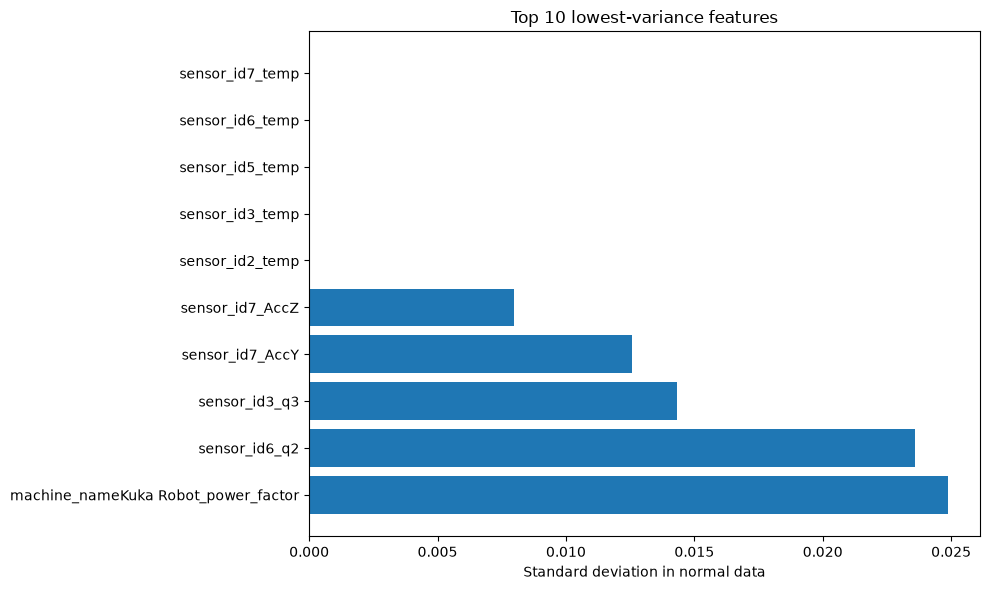

Constant features: 0
Near-constant features: 5


In [21]:
low_var_report_a = diag_a[[
    "feature", "std", "variance", "min", "max", "unique_values", "missing_pct"
]].copy()


low_var_report_a["is_constant"] = low_var_report_a["std"] == 0
low_var_report_a["is_near_constant"] = low_var_report_a["std"] < LOW_VARIANCE_THRESHOLD

low_var_report_a = low_var_report_a.sort_values("std", ascending=True)

display(
    low_var_report_a.head(TOP_K_LOW_VAR).style
    .background_gradient(subset=["std", "variance", "unique_values"], cmap="Blues")
    .format({
        "std": "{:.6e}",
        "variance": "{:.6e}",
        "min": "{:.6f}",
        "max": "{:.6f}",
        "missing_pct": "{:.2f}%",
    })
)

# Bar plot: lowest-variance features
plt.figure(figsize=(10, 6))
plot_df = low_var_report_a.head(TOP_K_LOW_VAR).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["std"])
plt.xlabel("Standard deviation in normal data")
plt.title(f"Top {TOP_K_LOW_VAR} lowest-variance features")
plt.tight_layout()
plt.show()

constant_features = low_var_report_a.loc[low_var_report_a["is_constant"], "feature"].tolist()
near_constant_features = low_var_report_a.loc[low_var_report_a["is_near_constant"], "feature"].tolist()

print(f"Constant features: {len(constant_features)}")
print(f"Near-constant features: {len(near_constant_features)}")

### **CONSIDERATIONS ON THE RESULTS**

After printing the standard deviation of all features and selecting the 5 features with the smallest std, we can see that the following features have a very low std and can therefore be considered almost constant:

- **NORMAL SAMPLES**

  | feature          | std          |
  |------------------|--------------|
  | sensor_id7_temp  | 1.502091e-10 |
  | sensor_id6_temp  | 1.502091e-10 |
  | sensor_id2_temp  | 3.284420e-10 |
  | sensor_id5_temp  | 3.284420e-10 |

- **ANOMALOUS SAMPLES**

  | feature          | std          |
  |------------------|--------------|
  | sensor_id2_temp  | 9.140532e-11 |
  | sensor_id3_temp  | 9.140532e-11 |
  | sensor_id5_temp  | 9.140532e-11 |
  | sensor_id6_temp  | 1.584814e-10 |
  | sensor_id7_temp  | 1.584814e-10 |

# **FEATURES RANGE ANALYSIS**

### Interpretation

For each feature:

* **`anom_inside_normal_minmax_pct`** indicates how often slow/anomalous values fall within the full normal min-max interval.
* **`anom_inside_normal_5_95_pct`** indicates how often slow/anomalous values fall within the normal central region.
* **`anom_outside_normal_5_95_pct`** indicates how often slow/anomalous values fall in the normal tails or beyond.
* **`anom_inside_range_but_tail_5_95_pct`** indicates how often slow/anomalous values still fall within the normal min-max interval, but lie exclusively in the normal tails.

This is useful because an anomaly can still lie inside the valid normal range, while still appearing in low-density regions.

In [22]:
# ------------------------------------------------------------
# 4. Range and tail report
# ------------------------------------------------------------

range_report = range_tail_report(df_n, df_a)

summary = pd.DataFrame({
    "metric": [
        "Average anomaly % inside normal min-max range",
        "Average anomaly % inside normal 5%-95% region",
        "Average anomaly % outside normal 5%-95% region",
        "Average anomaly % inside normal range but in 5%-95% tails",
        "Average anomaly % outside normal 1%-99% region",
    ],
    "value_pct": [
        range_report["anom_inside_normal_minmax_pct"].mean(),
        range_report["anom_inside_normal_5_95_pct"].mean(),
        range_report["anom_outside_normal_5_95_pct"].mean(),
        range_report["anom_inside_range_but_tail_5_95_pct"].mean(),
        range_report["anom_outside_normal_1_99_pct"].mean(),
    ]
})

print("Global summary across all features")
display(summary.style.format({"value_pct": "{:.2f}%"}))

Global summary across all features


,metric,value_pct
0,Average anomaly % inside normal min-max range,99.97%
1,Average anomaly % inside normal 5%-95% region,94.00%
2,Average anomaly % outside normal 5%-95% region,6.00%
3,Average anomaly % inside normal range but in 5%-95% tails,5.98%
4,Average anomaly % outside normal 1%-99% region,0.94%


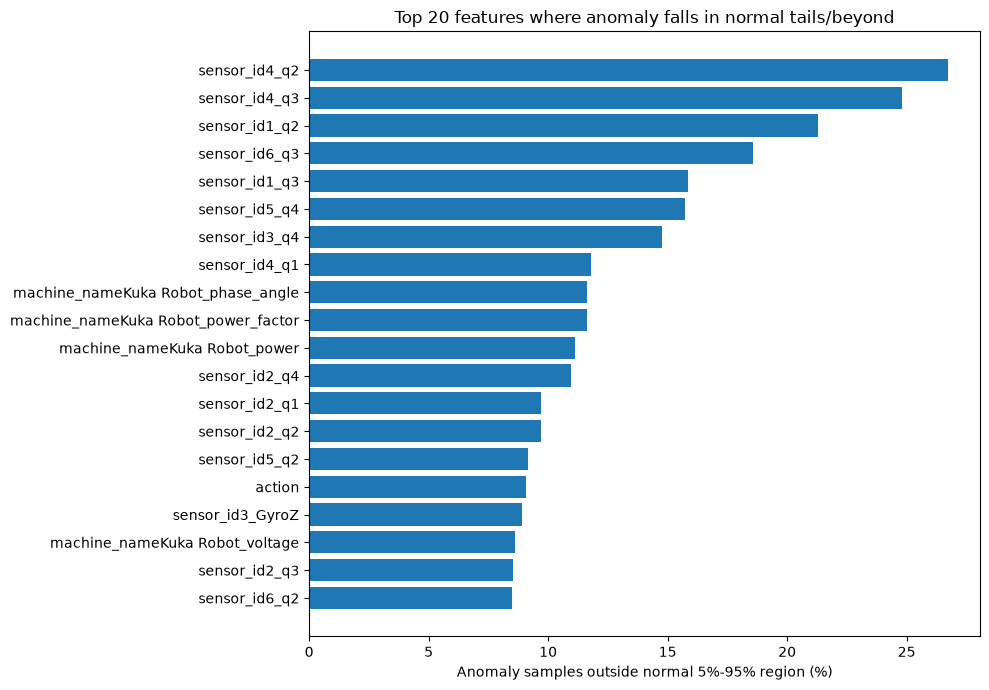

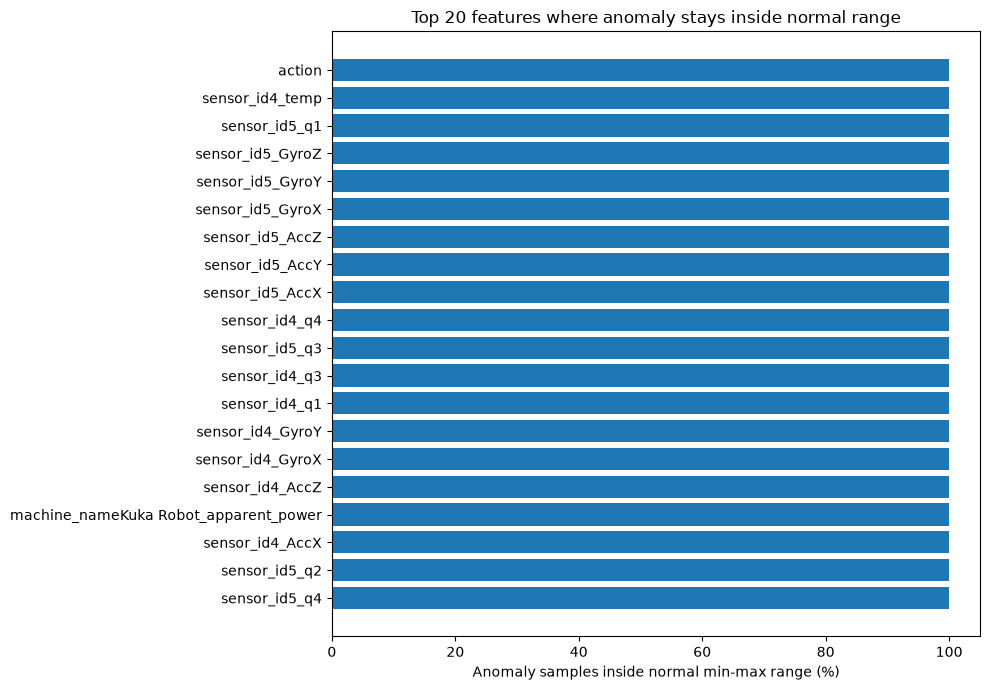

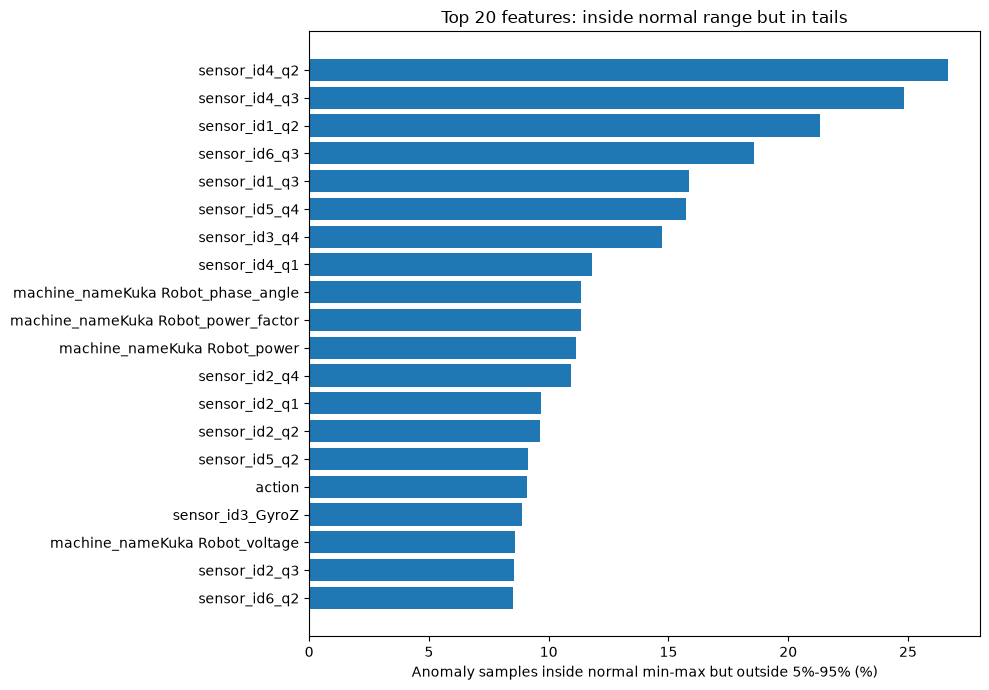

In [23]:
# ------------------------------------------------------------
# 5. Visualize range/tail behavior
# ------------------------------------------------------------

TOP_K = 20

# Top features where anomalies are most often outside the normal 5%-95% region
tail_top = range_report.sort_values(
    "anom_outside_normal_5_95_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    tail_top["feature"].iloc[::-1],
    tail_top["anom_outside_normal_5_95_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples outside normal 5%-95% region (%)")
plt.title(f"Top {TOP_K} features where anomaly falls in normal tails/beyond")
plt.tight_layout()
plt.show()


# Top features where anomalies are inside normal min-max range
inside_top = range_report.sort_values(
    "anom_inside_normal_minmax_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    inside_top["feature"].iloc[::-1],
    inside_top["anom_inside_normal_minmax_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples inside normal min-max range (%)")
plt.title(f"Top {TOP_K} features where anomaly stays inside normal range")
plt.tight_layout()
plt.show()


# Features where anomaly is inside range but concentrated in tails
inside_tail_top = range_report.sort_values(
    "anom_inside_range_but_tail_5_95_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    inside_tail_top["feature"].iloc[::-1],
    inside_tail_top["anom_inside_range_but_tail_5_95_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples inside normal min-max but outside 5%-95% (%)")
plt.title(f"Top {TOP_K} features: inside normal range but in tails")
plt.tight_layout()
plt.show()


### **POST-REPORT CONSIDERATIONS**

After printing the report of the features with the highest KS score, we can observe that the anomalous samples, for almost all 10 features, fall within the `[min_normal, max_normal]` range of values that we have for normal samples.

**Example:**

**FEATURE:** `sensor_id3_q1`

**FOR NORMAL SAMPLES:**
- minimum value = `-0.9999987292677391`
- maximum value = `0.6122537990951888`

**FOR ANOMALOUS SAMPLES:**
- minimum value = `-0.9999863030997028`
- maximum value = `-0.734394968606377`

As you can see, the range assumed by the anomalous samples falls within the range of the normal samples, so it is not easy to identify the anomaly from the value alone; we probably need to look at something related to **FREQUENCY, TIMING, PHASE (CYCLICITY)**.

# **TAIL RESIDENCE**

Let's observe how much the data remain outside the 5%-95% range. This is useful because in healthy behavior, the measurement may reach extreme values (e.g. motor torque spikes to the 97th percentile) but only briefly and then returns to the normal range. In the event of malfunctions, some values may spike to one of the two extremes and remain there for a prolonged time.

Alternatively, from the opposite perspective, it could happen that the robot needs to maintain a given value for a certain amount of time, and in case of an anomaly this value is maintained for less time than needed.

In [24]:
def run_lengths(mask):
    """
    mask: boolean array
    returns lengths of consecutive True runs
    """
    mask = np.asarray(mask).astype(bool)

    if len(mask) == 0:
        return np.array([])

    padded = np.concatenate([[False], mask, [False]])
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    return ends - starts


def tail_residence_report(df_n, df_a, q_low=0.05, q_high=0.95):
    rows = []

    for f in df_n.columns:
        x_n = df_n[f].dropna()
        x_a = df_a[f].dropna()

        low_thr = x_n.quantile(q_low)
        high_thr = x_n.quantile(q_high)

        n_tail = (df_n[f] < low_thr) | (df_n[f] > high_thr)
        a_tail = (df_a[f] < low_thr) | (df_a[f] > high_thr)

        n_runs = run_lengths(n_tail.values)
        a_runs = run_lengths(a_tail.values)

        rows.append({
            "feature": f,
            "normal_tail_pct": n_tail.mean() * 100,
            "anomaly_tail_pct": a_tail.mean() * 100,

            "normal_max_tail_run": n_runs.max() if len(n_runs) else 0,
            "anomaly_max_tail_run": a_runs.max() if len(a_runs) else 0,

            "normal_mean_tail_run": n_runs.mean() if len(n_runs) else 0,
            "anomaly_mean_tail_run": a_runs.mean() if len(a_runs) else 0,

            "tail_pct_ratio_anom_vs_normal": (
                a_tail.mean() / n_tail.mean() if n_tail.mean() > 0 else np.nan
            ),

            "max_run_ratio_anom_vs_normal": (
                (a_runs.max() / n_runs.max())
                if len(n_runs) and n_runs.max() > 0 and len(a_runs)
                else np.nan
            ),
        })

    return pd.DataFrame(rows).sort_values(
        ["max_run_ratio_anom_vs_normal", "tail_pct_ratio_anom_vs_normal"],
        ascending=False
    )


tail_report = tail_residence_report(df_n, df_a)

display(
    tail_report.head(30).style
    .background_gradient(
        subset=[
            "anomaly_tail_pct",
            "anomaly_max_tail_run",
            "tail_pct_ratio_anom_vs_normal",
            "max_run_ratio_anom_vs_normal",
        ],
        cmap="Oranges"
    )
    .format({
        "normal_tail_pct": "{:.2f}%",
        "anomaly_tail_pct": "{:.2f}%",
        "normal_mean_tail_run": "{:.2f}",
        "anomaly_mean_tail_run": "{:.2f}",
        "tail_pct_ratio_anom_vs_normal": "{:.2f}",
        "max_run_ratio_anom_vs_normal": "{:.2f}",
    })
)

,feature,normal_tail_pct,anomaly_tail_pct,normal_max_tail_run,anomaly_max_tail_run,normal_mean_tail_run,anomaly_mean_tail_run,tail_pct_ratio_anom_vs_normal,max_run_ratio_anom_vs_normal
29,sensor_id2_q4,10.00%,10.94%,57,97,40.24,49.93,1.09,1.70
49,sensor_id4_q2,10.00%,26.73%,91,137,26.57,53.38,2.67,1.51
40,sensor_id3_q4,10.00%,14.78%,52,71,7.65,10.83,1.48,1.37
32,sensor_id3_AccY,10.00%,5.45%,8,10,1.47,1.37,0.55,1.25
27,sensor_id2_q2,10.00%,9.69%,65,81,20.24,26.31,0.97,1.25
67,sensor_id6_GyroX,9.91%,4.69%,5,6,2.62,2.58,0.47,1.20
21,sensor_id2_AccY,9.97%,4.43%,5,6,1.65,1.66,0.44,1.20
24,sensor_id2_GyroY,9.99%,2.23%,10,11,3.47,2.94,0.22,1.10
22,sensor_id2_AccZ,9.25%,7.44%,12,13,1.98,2.12,0.80,1.08
44,sensor_id4_AccZ,9.36%,7.17%,12,13,1.95,2.20,0.77,1.08


### **CONSIDERATIONS**

By mathematical definition, if we take a data set and compute these percentiles, exactly 10% of the samples will always fall in those tails (5% below, 5% above). In this case, many features show tail residence different from 10% (higher or lower), which suggests a possible issue.

Example: looking at the `[normal-anomaly]_max_tail_run` metric (which measures the longest streak of consecutive samples whose measurements fall in the tails) for the feature `sensor_id4_q2`, we can see that the longest streak in the anomalous case is 137 (+46 compared with the normal case), showing a greater residence in the tail.

# **KOLMOGOROV-SMIRNOV ANALYSIS**

The **KS score (Kolmogorov-Smirnov)** is a statistic that measures how much two probability distributions differ from each other.

**How it works**

1. It takes the cumulative distribution functions (CDFs) of two samples (or of a sample compared with a theoretical distribution).
2. It computes the **maximum vertical distance** between the two CDF curves, point by point.
3. That maximum value is the KS score: a number between 0 and 1.
   - **KS close to 0** → the two distributions are very similar.
   - **KS close to 1** → the two distributions are very different.

**What it is used for in practice:**
- **Feature selection / binary classification**: in machine learning, KS can measure how well a feature separates two classes (e.g. the distribution of values for the positive class vs. the negative class) — the higher the KS, the more discriminative the feature is.
- **Comparison between two samples**: verify whether they come from the same distribution (e.g. training data vs. production data, to detect *data drift*).

In [25]:
ks_df = get_ks_df(df_n, df_a)
features = ks_df["feature"].tolist()

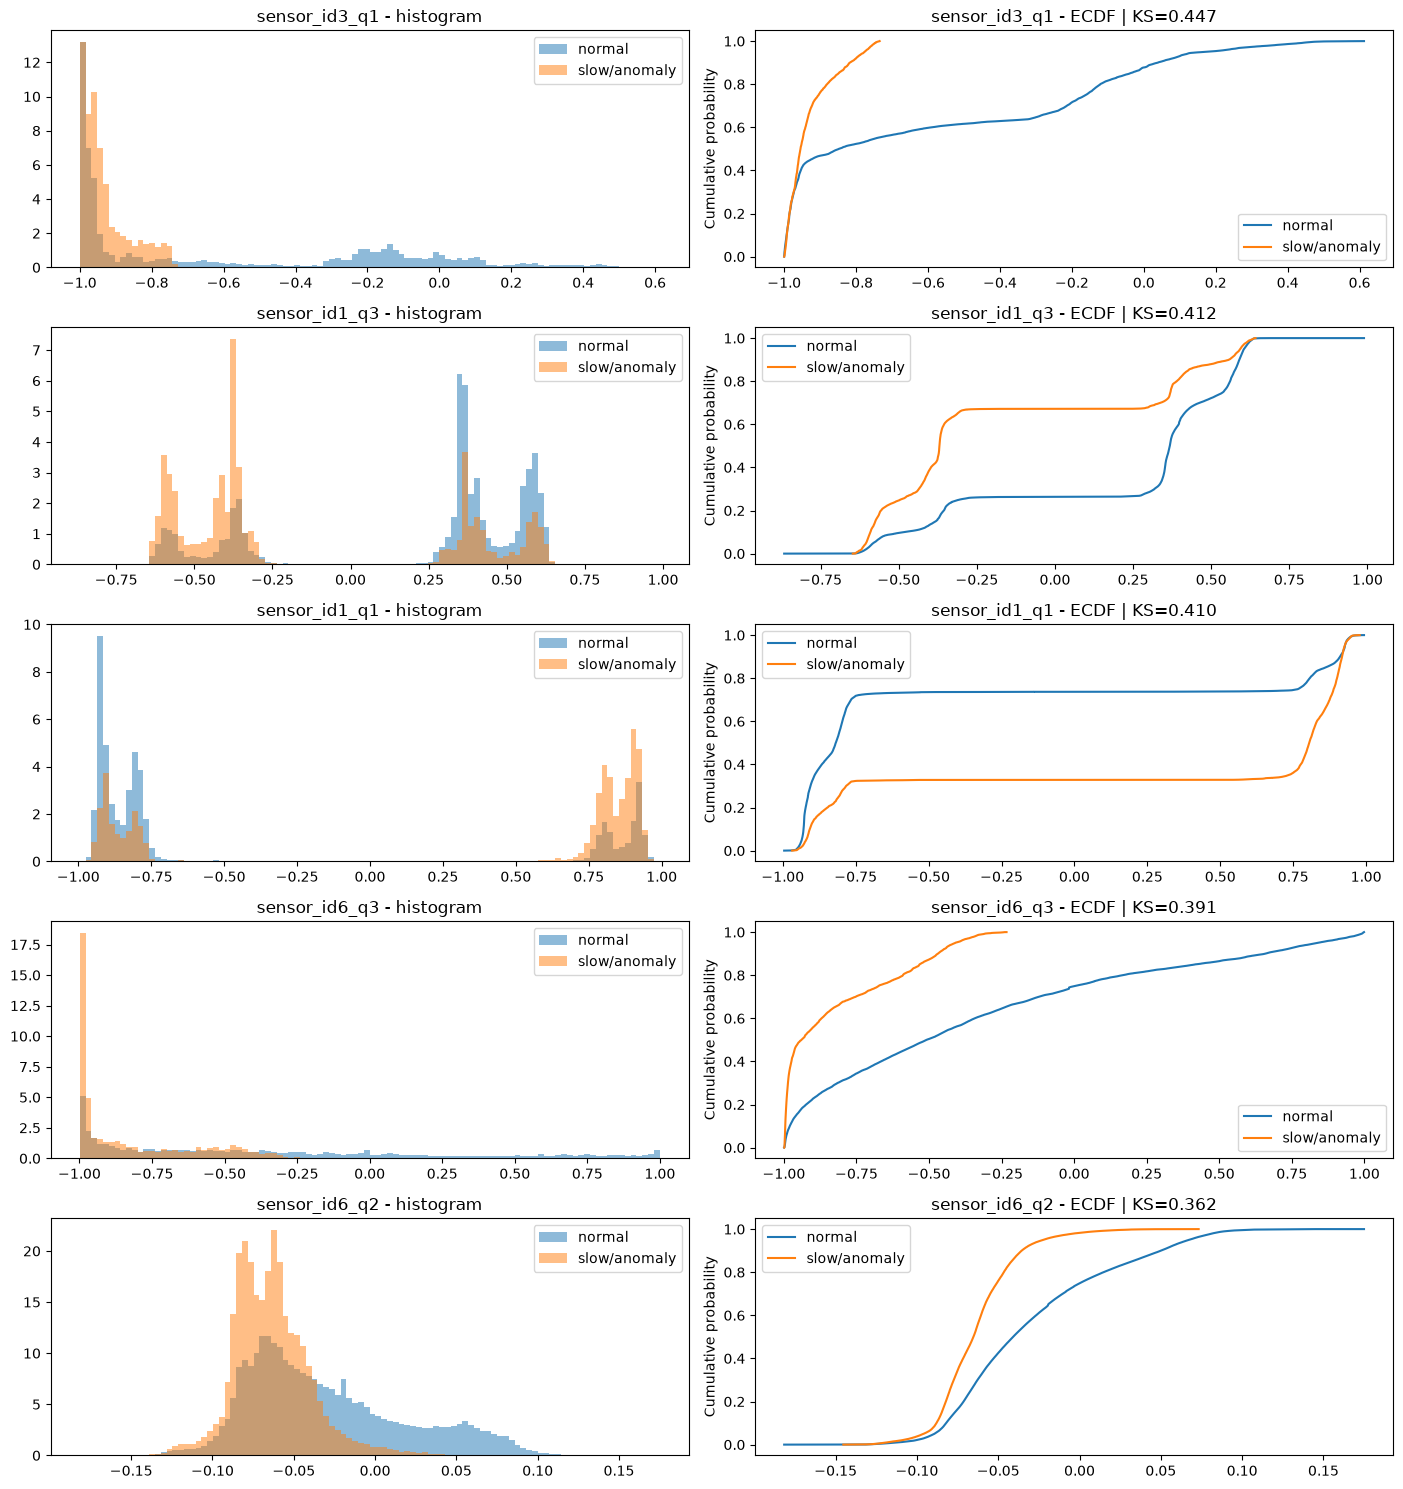

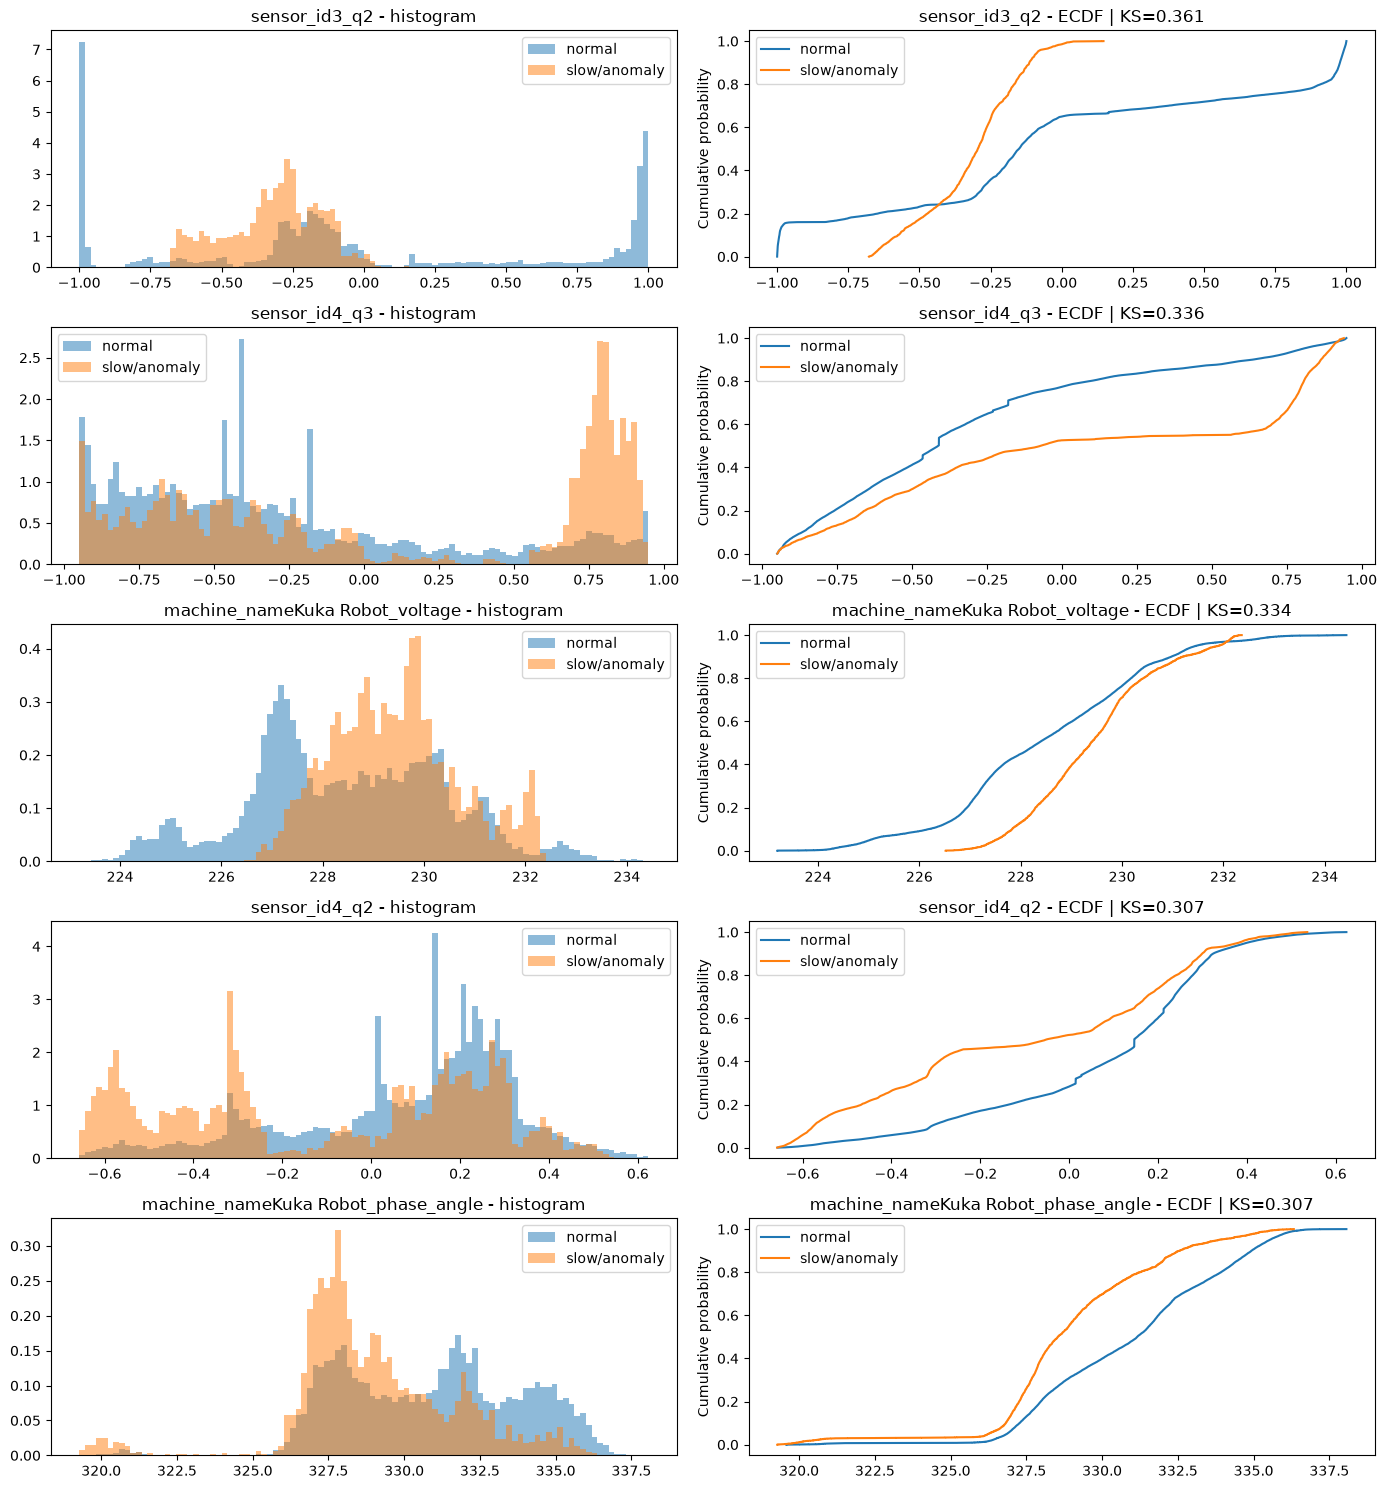

In [26]:
plot_most_separable_features(df_n, df_a, features)

# **TEMPORAL ANALYSIS**

With a line plot, we can actually observe the physical behavior.

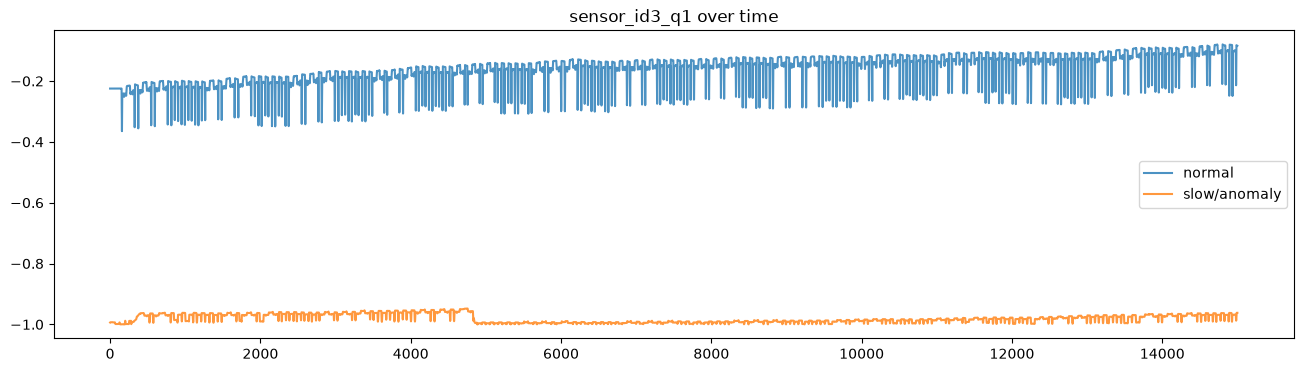

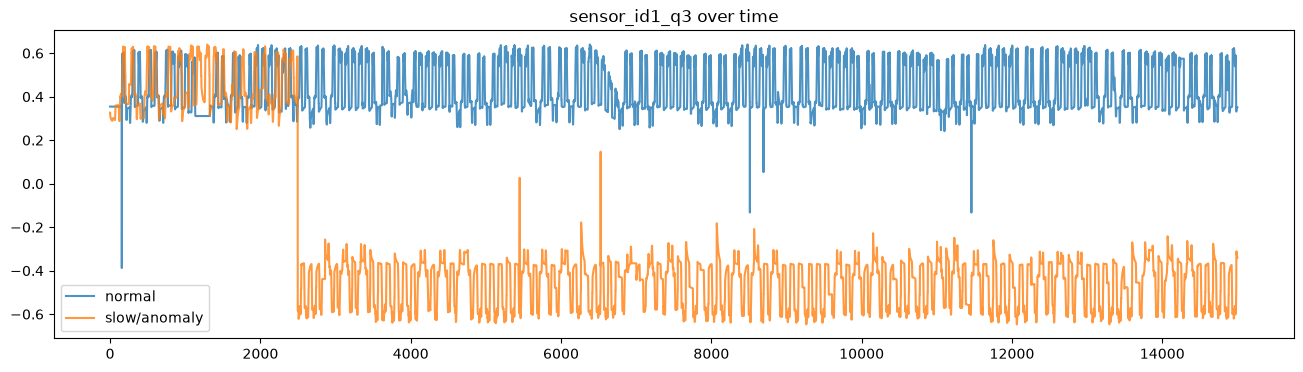

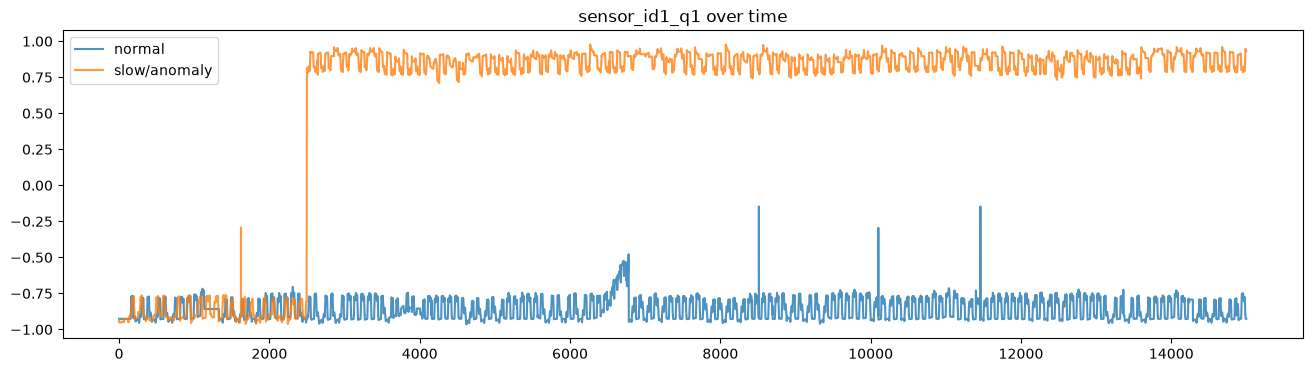

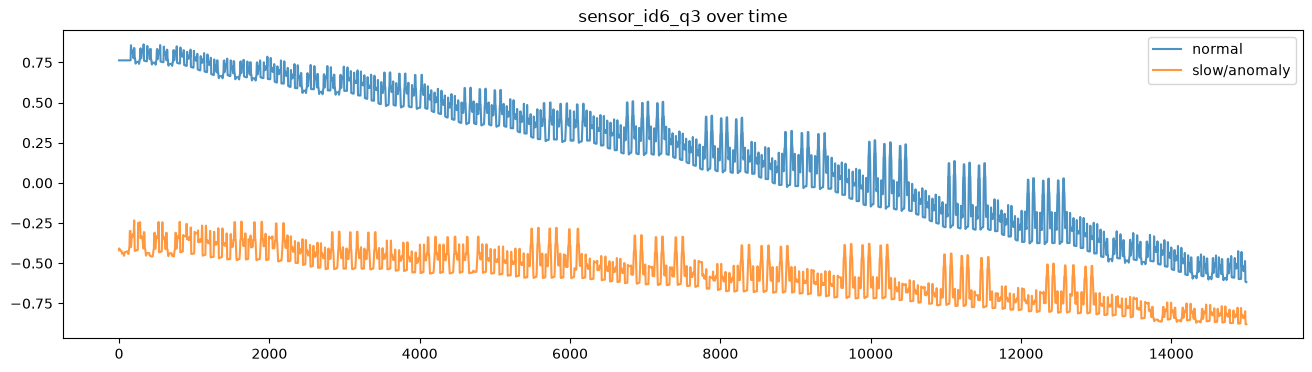

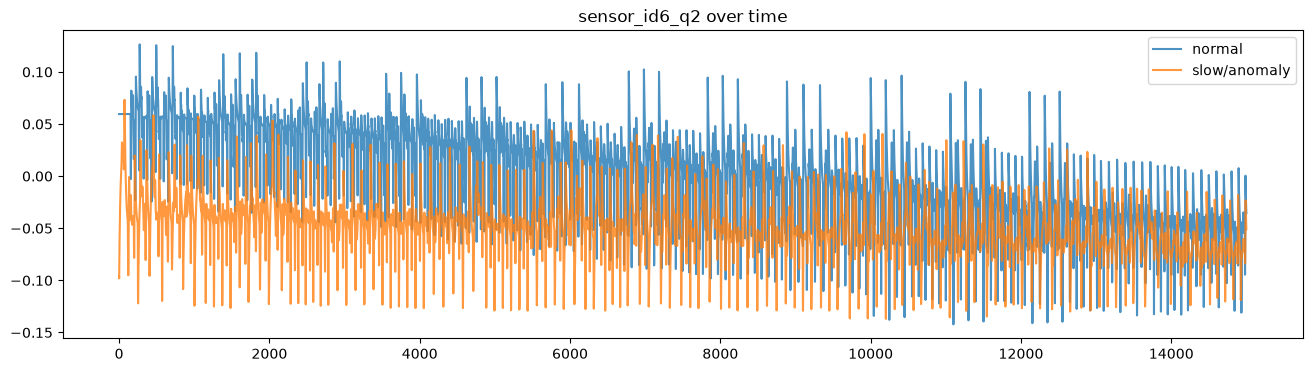

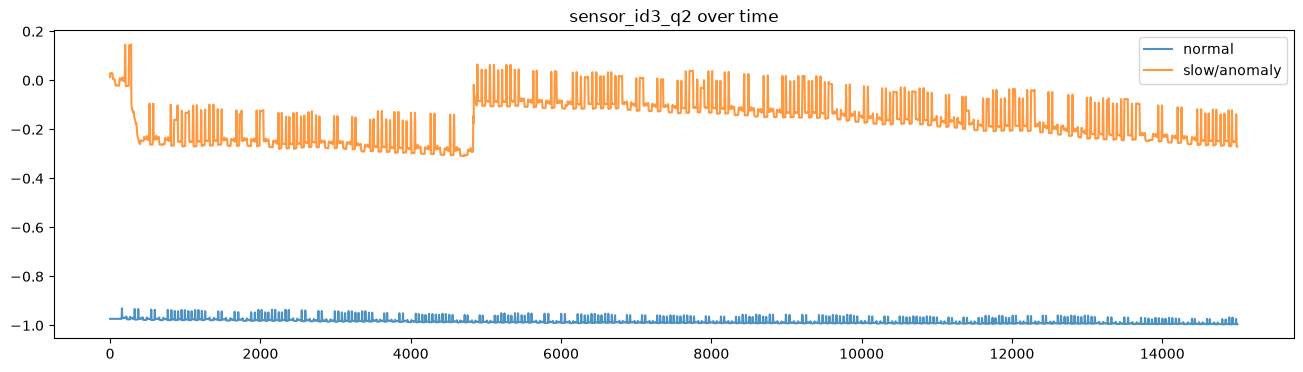

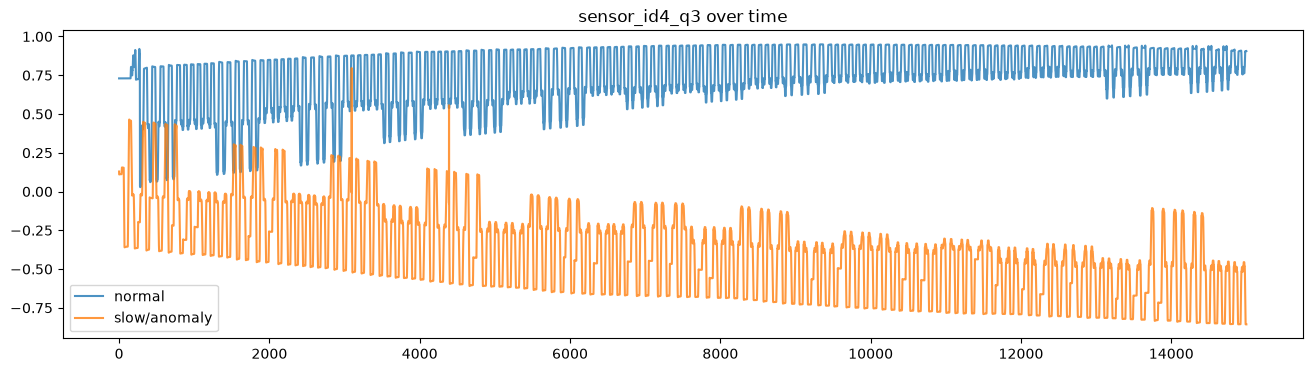

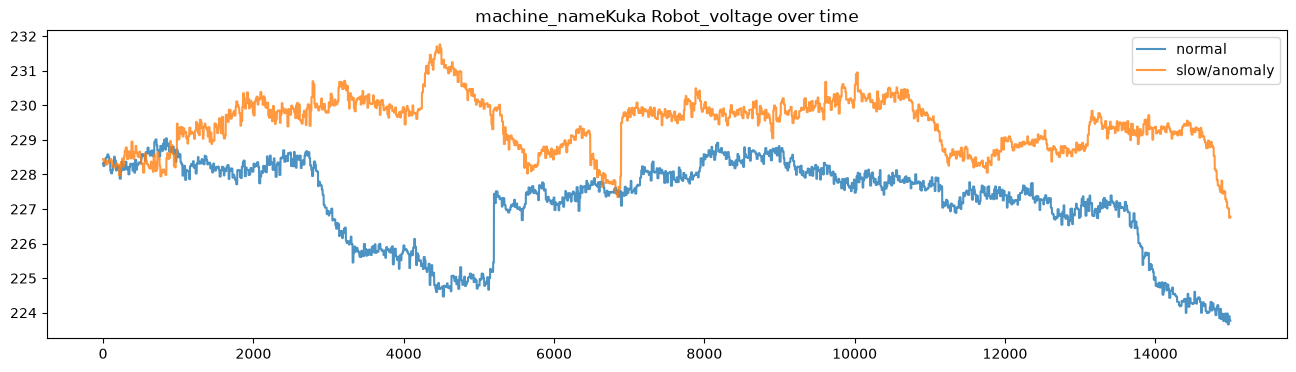

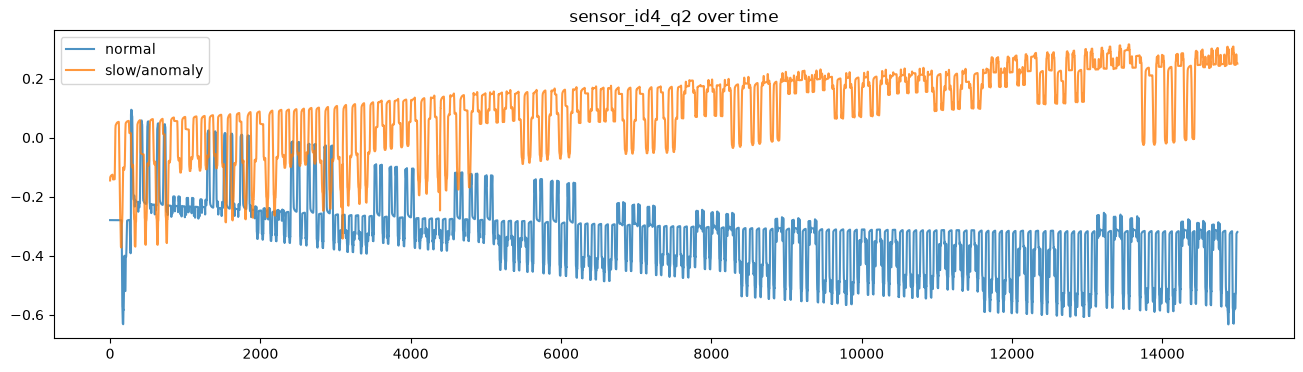

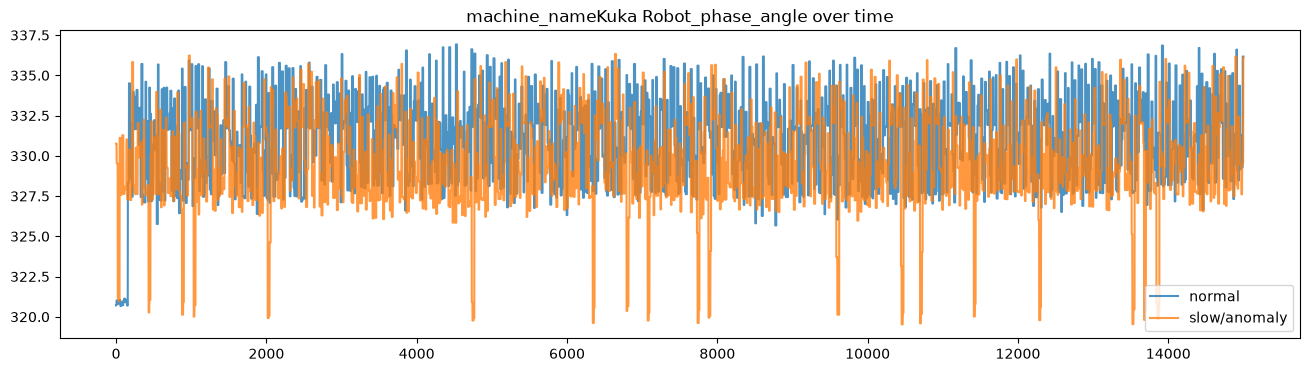

In [27]:
for f in features:
    plt.figure(figsize=(16, 4))
    plt.plot(df_n[f].values[:15000], label="normal", alpha=0.8)
    plt.plot(df_a[f].values[:15000], label="slow/anomaly", alpha=0.8)
    plt.title(f"{f} over time")
    plt.legend()
    plt.show()

### **PLOT ANALYSIS**
The situations that occurred are:
- **positional shift**: anomalous values are often shifted with respect to the normal version, which, in the case of measurements from sensors placed on the q joints (q1, q2, ...), means that the arm is positioned incorrectly and shifted relative to the normal position.
- **lack of motion**: in some cases the measurement over time becomes a straight line, which, in the case of the joints, means that there is no movement at all.
- **peak inversion**: for some features, when moving from anomaly to normal measurement, the robot shows peaks pointing in the opposite direction.

  (for example, look at the graph `sensors_id6_q2`: for normal samples, the blue peaks point upward, meaning the joint undergoes sudden accelerations/displacements in the positive direction. For anomalous samples, instead, the peaks point downward [-0.10/-0.15], meaning that position changes occur in the opposite direction)

  This could happen when the arm needs to balance an imbalance.

# **FIRST-DIFFERENCE ANALYSIS**

`.diff()` computes the difference between the value taken by a feature at time t and its value at time t-1. This is equivalent to computing the discrete derivative, so the meaning of the result changes depending on the meaning of the feature:
- if the feature was **positional** (e.g. the angle of a joint), the $\Delta$ represents the *velocity*;
- if the feature is **velocity**, the $\Delta$ represents the *acceleration*;
- if the feature is **torque** or **current**, the $\Delta$ represents the instantaneous variation in effort (useful for identifying jerks or current spikes).

In addition, `density=True` has been set, so we are comparing the probability density functions of the two conditions (normal vs. slow).

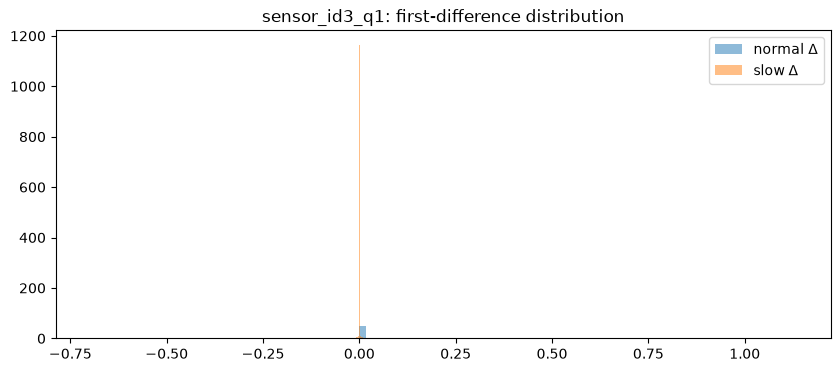

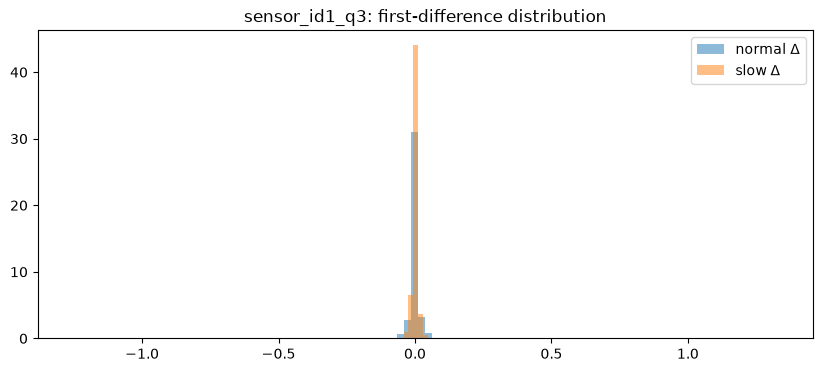

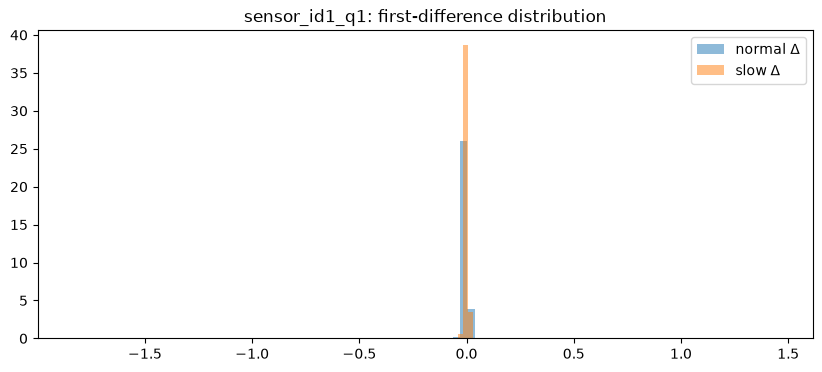

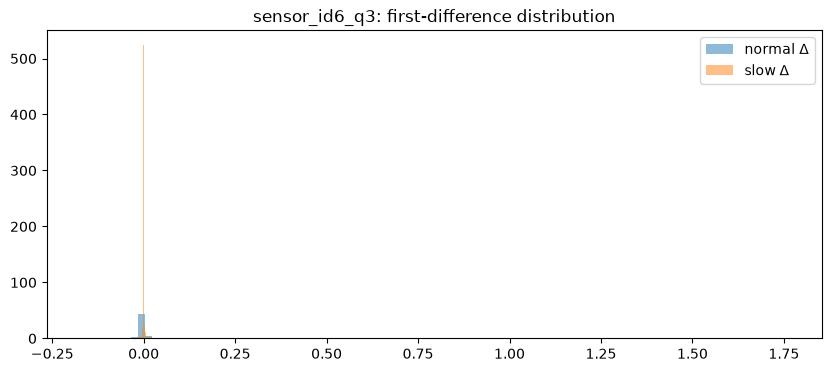

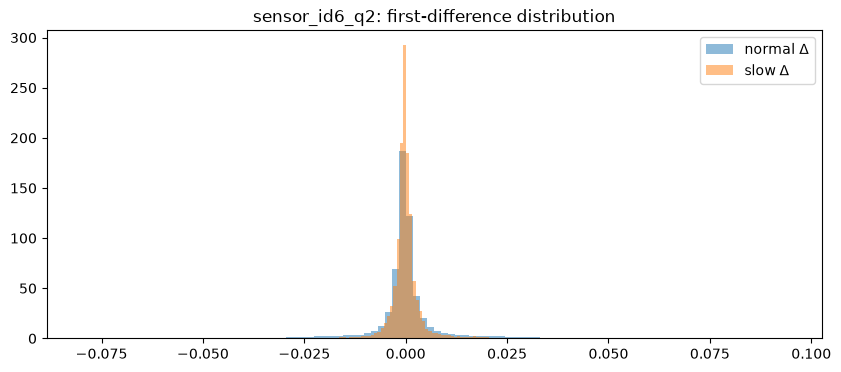

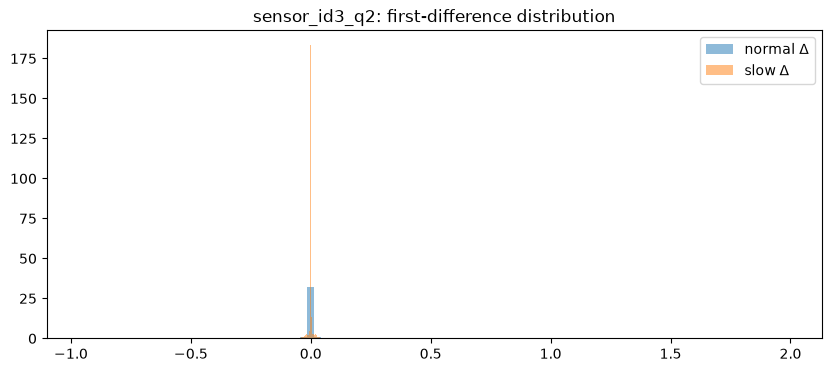

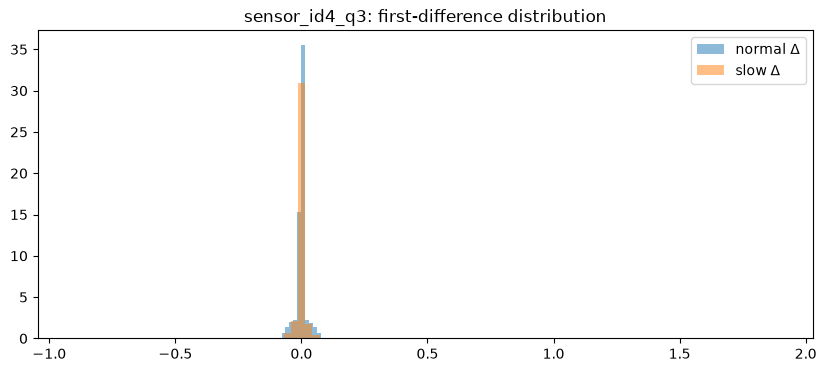

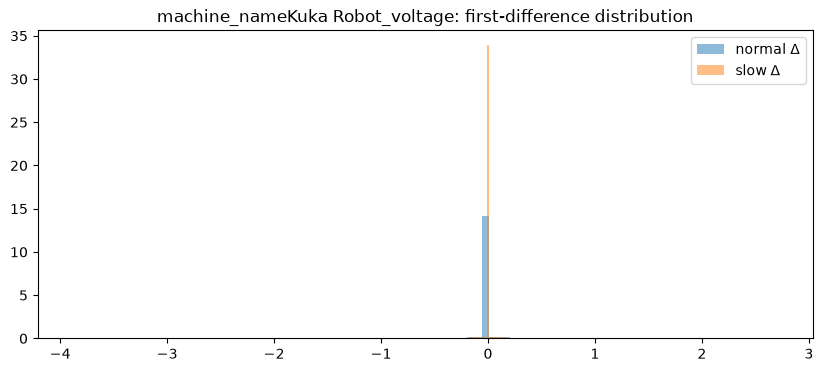

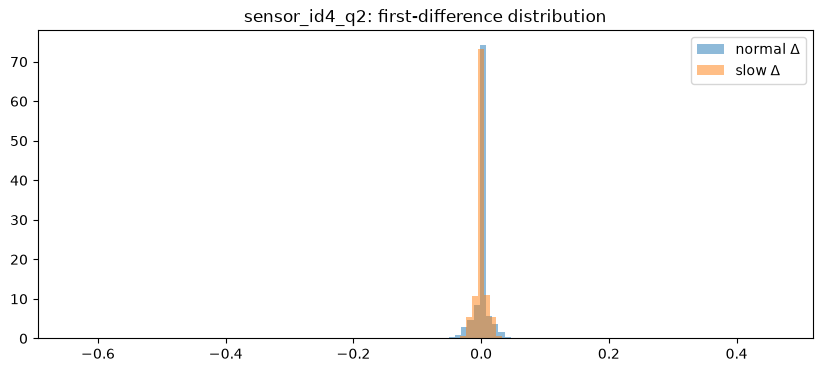

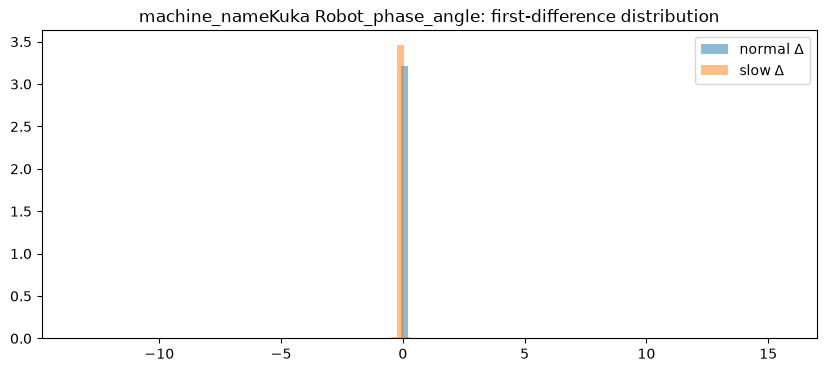

In [28]:
for f in features:
    dn = df_n[f].diff().dropna()
    da = df_a[f].diff().dropna()

    plt.figure(figsize=(10, 4))
    plt.hist(dn, bins=100, alpha=0.5, density=True, label="normal Δ")
    plt.hist(da, bins=100, alpha=0.5, density=True, label="slow Δ")
    plt.title(f"{f}: first-difference distribution")
    plt.legend()
    plt.show()

### **ANALYSIS OF THE PLOTS**

Here are the three patterns we encountered and their meanings:

- **The "slow" distribution is narrower and higher (concentrated around zero)**:

  - *What it means*: The values change much less from one sampling instant to the next.

  - *Interpretation*: This is the expected behavior for a purely "slow" anomaly. If the robot travels at reduced speed (e.g. because of a safety override or a slowdown imposed by the PLC), the variation in position or velocity at each time tick will be much smaller.

- **The "slow" distribution has thicker tails**:

  - *What it means*: There are more extreme values (positive and negative) in the rate of change.

  - *Interpretation*: This indicates jerky or vibrating motion. If the anomaly is caused by mechanical wear, friction, or a damaged joint, the robot will struggle to maintain smooth motion. Even if the overall motion is "slow", at each micro-instant the system undergoes sudden braking and acceleration, widening the histogram.

- **The distributions are shifted (mean shift)**:

  - *What it means*: The central peaks of the two histograms are not aligned.

  - *Interpretation*: There is a drift or an anomalous directional trend. In the case of positions, it means the robot is deviating; in the case of currents, it means the motor is constantly increasing or decreasing the effort in a specific direction with respect to the baseline.